# U.S. extended feature experiments

Compare the frozen HGB v1 with small feature groups on the 26,945 official training campaigns. Rewards and titles are snapshot experiments, not approved launch features. Listed city frequency is a planning-input candidate subject to the same location assumption as v1. No reserved labels, new split, model serialization or Streamlit changes.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'utils').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from scripts.review_launch_inputs import review
from utils.us_modeling import load_us_training_data
from utils.us_extended_features import compare_features
from utils.us_validation import candidates
from utils.us_prediction import USPredictor
import numpy as np
import joblib
import hashlib
import json

OUT = ROOT / 'docs/launch_feature_results'
OUT.mkdir(exist_ok=True)
X, y, ids = load_us_training_data(ROOT)
inputs = review()
(OUT / 'input_review.txt').write_text(json.dumps(inputs, indent=2) + '\n')
print(inputs['environment'])
print({k: inputs['training_source'][k] for k in ['training_rows', 'reward_missing', 'count_mismatch', 'parser_disagreement', 'title_replacement_characters']})

{'python': '3.12.3', 'sklearn': '1.9.1', 'numpy': '2.5.3', 'pandas': '3.0.5', 'joblib': '1.6.0', 'xgboost_installed': True, 'lightgbm_installed': True}
{'training_rows': 26945, 'reward_missing': 28, 'count_mismatch': 0, 'parser_disagreement': 0, 'title_replacement_characters': 366}


## Definitions and checks

Reward count is the number of positive finite dollar amounts parsed from `reward levels`. Empty lists have count zero and missing amount summaries. Amounts use log1p; relative amounts subtract log1p(goal). No activity or reward quantities enter these features. The existing parser accepts thousands separators and ignores malformed chunks; agreement on this dataset does not establish launch-time provenance.

Title length uses characters and whitespace-separated words. Style uses ASCII uppercase/alphabetic ratio (zero without letters), digit presence, ASCII punctuation count and exclamation count. Missing titles become empty strings. These definitions do not claim language-independent text quality. `name` may reflect later edits.

Listed city/state frequency is log1p of its training-fold count, with zero for unseen strings. It is not city population, historical completed-project count or a causal measure.

In [2]:
# Confirm exact frozen baseline and saved-model consistency without writing v1.
original = candidates()['HGB tuned'].fit(X, y)
path = ROOT / 'models/us_primary_model_v1.joblib'
metadata_path = path.with_suffix('.metadata.json')
protected = {p: hashlib.sha256(p.read_bytes()).hexdigest() for p in [path, metadata_path]}
saved = joblib.load(path)
np.testing.assert_array_equal(original.predict_proba(X), saved.predict_proba(X))
predictor = USPredictor(path)
for i in [0, 100, 1000]:
    row = X.iloc[i]
    response = predictor.predict(row.to_dict())
    np.testing.assert_allclose(response['success_probability'], saved.predict_proba(X.iloc[[i]])[0, 1], rtol=0, atol=0)
print('Frozen baseline probabilities match on all training rows; interface checks pass.')

Frozen baseline probabilities match on all training rows; interface checks pass.


## Comparison plan

Use the previous three stratified outer folds (seed 20261027) and two inner folds (seed 100 + outer fold). Fixed singles share the same outer partitions. Every fit includes fresh category goal medians, imputation, scaling and cross-fitted target encoding. HGB settings and threshold 0.5 stay fixed.

Inside each outer training partition, compare individual groups. Only groups passing +0.003 accuracy, at most 0.002 AUC loss and at most 0.01 failure-recall loss can form one pair of the two strongest groups. Compare that pair inside the inner folds too. The exploratory selector chooses the strongest eligible configuration; the approved selector considers only baseline and listed city frequency. These selectors keep outer validation separate from combination selection. The fixed singles are descriptive comparisons, not independent model-selection evidence.

Outer results have already informed earlier development. Trying several groups and reviewing these results adds selection bias; nested selection here does not undo previous exposure. Three overlapping folds provide no significance test or confidence interval. Snapshot features remain ineligible for production regardless of their scores. No optional booster is installed, so no dependency changes or extra search is needed.

In [3]:
summary, folds, inner = compare_features(X, y)
summary.index.name = 'configuration'
summary.to_csv(OUT / 'summary.csv')
folds.to_csv(OUT / 'outer_folds.csv', index=False)
inner.to_csv(OUT / 'inner_comparisons.csv', index=False)
display(summary.round(4))

Extended features: outer fold 1/3 complete
Extended features: outer fold 2/3 complete
Extended features: outer fold 3/3 complete


,accuracy,roc_auc,brier,tn,fp,fn,tp,failure_precision,failure_recall,failure_f1,failure_support,success_precision,success_recall,success_f1,success_support,fit_seconds,predict_seconds
configuration,,,,,,,,,,,,,,,,,
baseline,0.6693,0.7239,0.2096,6814.0,5415.0,3495.0,11221.0,0.6610,0.5572,0.6047,12229.0,0.6745,0.7625,0.7158,14716.0,0.3790,0.0627
reward_count,0.7015,0.7597,0.1959,7220.0,5009.0,3033.0,11683.0,0.7042,0.5904,0.6423,12229.0,0.6999,0.7939,0.7440,14716.0,0.6596,0.2062
reward_amounts,0.6948,0.7528,0.1989,7167.0,5062.0,3162.0,11554.0,0.6939,0.5861,0.6354,12229.0,0.6954,0.7851,0.7375,14716.0,0.7503,0.2112
reward_relative,0.6922,0.7509,0.1996,7102.0,5127.0,3166.0,11550.0,0.6917,0.5808,0.6314,12229.0,0.6926,0.7849,0.7358,14716.0,0.6954,0.1990
title_length,0.6723,0.7247,0.2094,6856.0,5373.0,3458.0,11258.0,0.6647,0.5606,0.6083,12229.0,0.6769,0.7650,0.7183,14716.0,0.4110,0.0862
title_style,0.6726,0.7265,0.2089,6887.0,5342.0,3481.0,11235.0,0.6643,0.5632,0.6095,12229.0,0.6777,0.7635,0.7181,14716.0,0.4663,0.0985
city_frequency,0.6770,0.7323,0.2068,6990.0,5239.0,3463.0,11253.0,0.6687,0.5716,0.6163,12229.0,0.6823,0.7647,0.7212,14716.0,0.3934,0.0927
exploratory_selection,0.7089,0.7697,0.1920,7329.0,4900.0,2943.0,11773.0,0.7135,0.5993,0.6514,12229.0,0.7061,0.8000,0.7501,14716.0,0.8002,0.2249
approved_selection,0.6770,0.7323,0.2068,6990.0,5239.0,3463.0,11253.0,0.6687,0.5716,0.6163,12229.0,0.6823,0.7647,0.7212,14716.0,0.3934,0.0927


configuration,approved_selection,baseline,city_frequency,exploratory_selection,inner_supported_pair,reward_amounts,reward_count,reward_relative,title_length,title_style
fold,,,,,,,,,,
1,0.0065,0.0,0.0065,0.0404,0.0404,0.0262,0.0341,0.0228,0.0024,0.0037
2,0.0116,0.0,0.0116,0.0382,0.0382,0.0265,0.0330,0.0259,0.0036,0.0051
3,0.0051,0.0,0.0051,0.0402,0.0402,0.0237,0.0296,0.0199,0.0028,0.0009


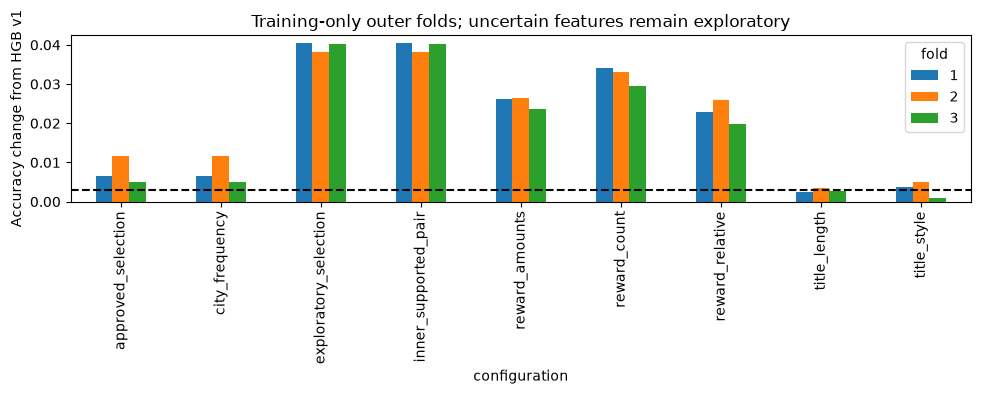

In [4]:
paired = folds.pivot(index='fold', columns='configuration', values='accuracy')
deltas = paired.subtract(paired['baseline'], axis=0)
deltas.to_csv(OUT / 'paired_accuracy.csv')
display(deltas.round(4))
ax = deltas.drop(columns='baseline').T.plot.bar(figsize=(10, 4))
ax.axhline(.003, color='black', linestyle='--', label='minimum gain')
ax.set_ylabel('Accuracy change from HGB v1')
ax.set_title('Training-only outer folds; uncertain features remain exploratory')
plt.tight_layout()
plt.savefig(OUT / 'paired_accuracy.png', dpi=140)
plt.show()

## Decision

HGB v1 reproduces 66.93% accuracy, .7239 AUC and 55.72% failure recall. City frequency reaches 67.70%, .7323 and 57.16%, improving accuracy in all three folds. The inner approved-input selector chose it in every fold. Keep v1 primary and review the separate city candidate with Zasha before changing the input contract.

Reward count reaches 70.15% accuracy; the exploratory nested procedure reaches 70.89%. These snapshot features remain ineligible for production. Title length misses the .003 accuracy guardrail; title style passes it narrowly but lacks verified launch provenance. No significance or causal claim follows.

No candidate is serialized by this notebook. The separate guarded candidate script saves city v2 only after these results, with round-trip verification. Global currency and location semantics remain unresolved; the global dashboard option stays unavailable.

In [5]:
for p, before in protected.items():
    assert hashlib.sha256(p.read_bytes()).hexdigest() == before
print('v1 model and metadata unchanged. No reserved labels or predictions used.')

v1 model and metadata unchanged. No reserved labels or predictions used.
